In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
sys.path.append("version2/Co60_Lead")
from peak_significance import*

In [5]:
!python spc_to_csv-new.py Co60-NoLead.Spc
!python spc_to_csv-new.py Co60-Lead.Spc

Wrote 8192 channels to Co60-NoLead.csv
live time 3601 s, real time 3649 s, total counts 3,173,688
Wrote 8192 channels to Co60-Lead.csv
live time 3601 s, real time 3645 s, total counts 2,907,479


In [2]:
Best model by p-value (fewer params on ties): per-source offsets
  E = a1*ch + a0[source]
  chi2/ndf = 7.580/8  (red = 0.947, p = 0.476)
  a1 = 0.215104 +/- 0.000005 keV/channel
  a0 = 31.7144 +/- 0.0303 keV
  Per-source offsets (relative to Co60):
    Eu152: +1.1349 +/- 0.0208 keV

SyntaxError: invalid syntax (1828458014.py, line 1)

In [3]:
coeffs = 31.7144, 0.215104
ch_l, n_l, L_l = load_run("Co60-Lead.csv")
ch_b, n_b, L_b = load_run("Co60-NoLead.csv")
print("live times (s):", L_l, L_b)

live times (s): 3601.0 3601.0


In [4]:
check_lines(ch_l, n_l, coeffs)
check_lines(ch_b, n_b, coeffs)

 1173.23 keV: predicted ch   5306.8, strongest bin     5300, offset -6.8 ch
 1332.49 keV: predicted ch   6047.2, strongest bin     6039, offset -8.2 ch
 1173.23 keV: predicted ch   5306.8, strongest bin     5292, offset -14.8 ch
 1332.49 keV: predicted ch   6047.2, strongest bin     6033, offset -14.2 ch


In [5]:
m, c, table, ch_of = run_calibration(ch_l, n_l, coeffs, energies=(1173.23, 1332.49), verbose=True)
mu_l = ch_of(511.0)                      # 511 keV channel for THIS run

m, c, table, ch_of = run_calibration(ch_b, n_b, coeffs, energies=(1173.23, 1332.49), verbose=True)
mu_b = ch_of(511.0)       # and for the blank

print(mu_l, mu_b)

  E_keV  centroid  centroid_err  fwhm_ch  resid_ch
1173.23   5299.89          0.01    11.99       0.0
1332.49   6039.48          0.01    12.70       0.0
  channel = 4.6439 * E + -148.47   (channel of 0 keV: -148.5)
  E_keV  centroid  centroid_err  fwhm_ch  resid_ch
1173.23   5291.00          0.01    13.91       0.0
1332.49   6029.34          0.01    15.15       0.0
  channel = 4.6361 * E + -148.17   (channel of 0 keV: -148.2)
2224.561831041 2220.859128932976


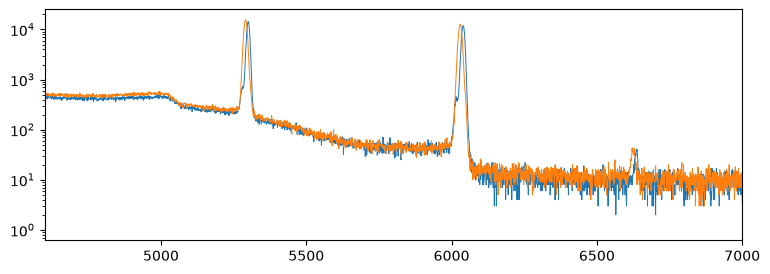

In [6]:
plt.figure(figsize=(9,3))
plt.semilogy(ch_l, n_l, lw=0.7); plt.xlim(4600, 7000)
plt.semilogy(ch_b, n_b, lw=0.7); plt.xlim(4600, 7000)
plt.show()

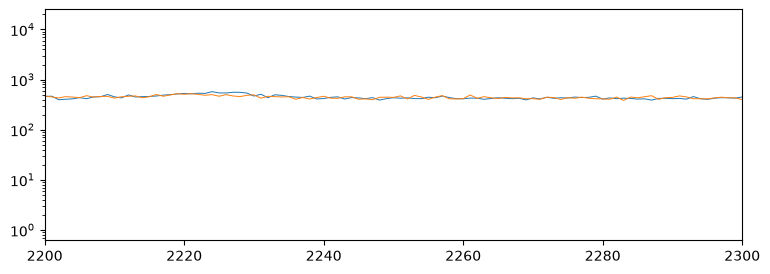

In [7]:
plt.figure(figsize=(9,3))
plt.semilogy(ch_l, n_l, lw=0.7); plt.xlim(2200, 2300)
plt.semilogy(ch_b, n_b, lw=0.7); plt.xlim(2200, 2300)
plt.show()

In [13]:
mu = channel_of(511.0, coeffs)
# width from your resolution fit
fwhm_keV = np.sqrt(21.746 + -0.0097 * 511.0)  # used data from resolution results .
slope = coeffs[1]                       # keV per channel (linear calibration)
sigma = fwhm_keV / slope / 2.355        # in channels
print(mu, sigma)

2228.1575423980958 8.088665888684174


In [14]:
fl = peak_fit(ch_l, n_l, mu, sigma)
fb = peak_fit(ch_b, n_b, mu, sigma)
print(f"with lead: area {fl['area']:.0f} +/- {fl['area_err']:.0f}, Z = {fl['Z']:.1f} sigma")
print(f"blank   : area {fb['area']:.0f} +/- {fb['area_err']:.0f}, Z = {fb['Z']:.1f} sigma")

rate_l, rate_b = fl['area']/L_l, fb['area']/L_b
err = np.hypot(fl['area_err']/L_l, fb['area_err']/L_b)
print(f"excess 511 rate (lead - blank): {rate_l-rate_b:.4f} +/- {err:.4f} per second "
      f"= {(rate_l-rate_b)/err:.1f} sigma")

with lead: area 1987 +/- 127, Z = 15.6 sigma
blank   : area 951 +/- 129, Z = 7.4 sigma
excess 511 rate (lead - blank): 0.2879 +/- 0.0503 per second = 5.7 sigma


In [15]:
fl = peak_fit(ch_l, n_l, mu_l, sigma)
fb = peak_fit(ch_b, n_b, mu_b, sigma)
print(f"with lead: area {fl['area']:.0f} +/- {fl['area_err']:.0f}, Z = {fl['Z']:.1f} sigma")
print(f"blank   : area {fb['area']:.0f} +/- {fb['area_err']:.0f}, Z = {fb['Z']:.1f} sigma")

rate_l, rate_b = fl['area']/L_l, fb['area']/L_b
err = np.hypot(fl['area_err']/L_l, fb['area_err']/L_b)
print(f"excess 511 rate (lead - blank): {rate_l-rate_b:.4f} +/- {err:.4f} per second "
      f"= {(rate_l-rate_b)/err:.1f} sigma")

with lead: area 2164 +/- 127, Z = 17.0 sigma
blank   : area 1 +/- 3, Z = 0.4 sigma
excess 511 rate (lead - blank): 0.6006 +/- 0.0353 per second = 17.0 sigma


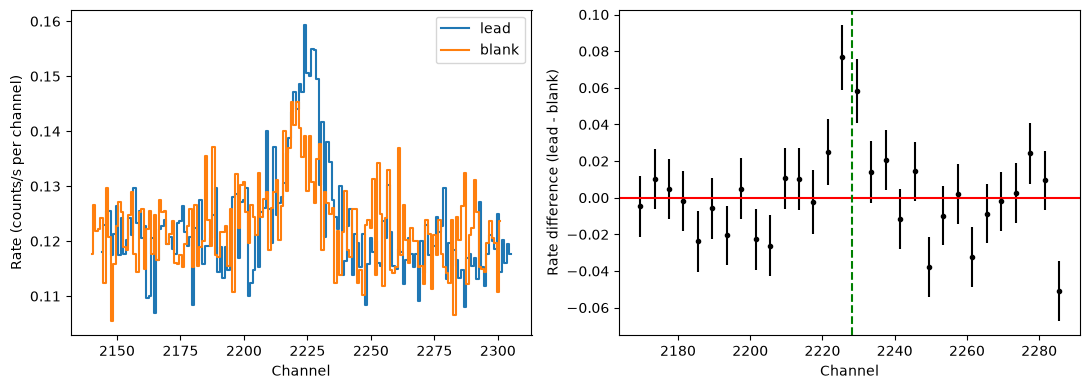

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, f, t in [(ax[0], fl, "with tin"), (ax[0], fb, "blank")]:
    pass
ax[0].step(fl['x'], fl['y']/L_l, where="mid", label="lead"); ax[0].step(fb['x'], fb['y']/L_b, where="mid", label="blank")
ax[0].set_xlabel("Channel"); ax[0].set_ylabel("Rate (counts/s per channel)"); ax[0].legend()
c, d, e = difference_spectrum(ch_l, n_l, L_l, n_b, L_b, rebin=4)
m = (c > mu - 60) & (c < mu + 60)
ax[1].errorbar(c[m], d[m], yerr=e[m], fmt=".", color="k"); ax[1].axhline(0, color="r"); ax[1].axvline(mu, color="g", ls="--")
ax[1].set_xlabel("Channel"); ax[1].set_ylabel("Rate difference (lead - blank)")
plt.tight_layout()

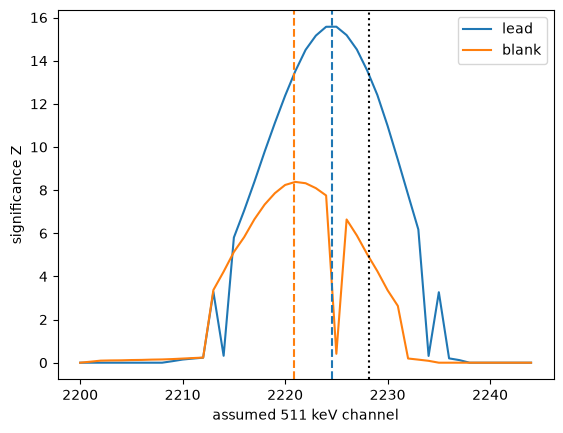

In [17]:
sigma_try = 4.5            # a sensible width, see below
for name, (ch, n, mu0) in {"lead": (ch_l, n_l, mu_l), "blank": (ch_b, n_b, mu_b)}.items():
    mus = np.arange(2200, 2245, 1.0)
    Zs = [peak_fit(ch, n, m, sigma_try)["Z"] for m in mus]
    plt.plot(mus, Zs, label=name)
plt.axvline(mu_l, color="C0", ls="--"); plt.axvline(mu_b, color="C1", ls="--"); plt.axvline(2228.16, color="k", ls=":")
plt.xlabel("assumed 511 keV channel"); plt.ylabel("significance Z"); plt.legend(); plt.show()